## Title: Heart Disease Prediction
Author: Muhammad Talha Imran\
[Linkedin](https://www.linkedin.com/in/talha-imran-ai)\
[Github](https://github.com/mtalhaimran104)\
Date: 10.Oct.2026

### Import Libraries
Let's start importing libraries used in project

In [134]:
# import libraries

# To handle the data
import pandas as pd
import numpy as np

# To visualize the dataset
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.express import scatter

# To preprocess the data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# import iterative imputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

# For classification task
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier, RandomForestRegressor
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_absolute_error, precision_score, r2_score, mean_squared_error

# import warnings
import warnings
warnings.filterwarnings('ignore')

### Load the dataset

In [135]:
# Load dataset
df = pd.read_csv('dataset/heart_disease_uci.csv')
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


### Exploratory Data Analysis (EDA)

In [136]:
# exploring the datatype of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [137]:
# data shape
df.shape

(920, 16)

In [138]:
# id column
df['id'].min(), df['id'].max()

(np.int64(1), np.int64(920))

In [139]:
# age column

# for minimum age
print("Minimum age is:",df['age'].min())

# for maximum age
print("Maximum age is:", df['age'].max())

Minimum age is: 28
Maximum age is: 77


In [140]:
# summarize the age column
df['age'].describe()

count    920.000000
mean      53.510870
std        9.424685
min       28.000000
25%       47.000000
50%       54.000000
75%       60.000000
max       77.000000
Name: age, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

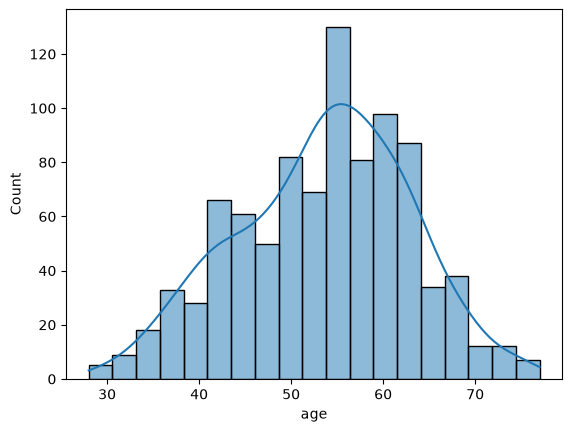

In [141]:
# draw a histogram to see distribution of age column
sns.histplot(df['age'], kde= True)

Mean: 53.51086956521739
Median: 54.0
Mode: 54


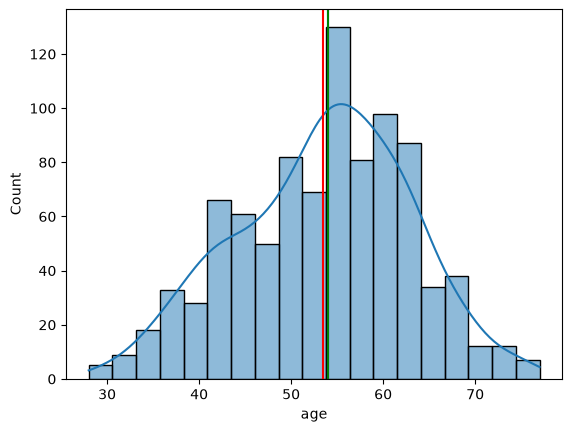

In [142]:
# plot the mean, median, mode of age column
sns.histplot(df['age'], kde=True)
plt.axvline(df['age'].mean(), color= 'red')
plt.axvline(df['age'].median(), color= 'blue')
plt.axvline(df['age'].mode()[0], color= 'green')

# print value of mean, median, mode of age column
print('Mean:', df['age'].mean())
print('Median:', df['age'].median())
print('Mode:', df['age'].mode()[0])

In [143]:
# plot the histogram of age column using plotly and coloring this by sex

fig = px.histogram(data_frame=df, x='age', color='sex')
fig.show()

In [144]:
# find the values of sex column
df['sex'].value_counts()

sex
Male      726
Female    194
Name: count, dtype: int64

In [145]:
# calculate percentage of male and female value counts in the data
male_count= 726
female_count = 194
total_count = male_count+ female_count

# calculate percentage
male_percentage = (male_count / total_count) * 100
female_percentage = (female_count / total_count) * 100

# display results
print(f'Male percentage in data: {male_percentage:.2f}%')
print(f'female percentage in data: {female_percentage:.2f}%')

# difference
difference_percentage = ((male_count - female_count) / female_count) * 100
print(f'Males are: {difference_percentage:.2f}% more than females')

Male percentage in data: 78.91%
female percentage in data: 21.09%
Males are: 274.23% more than females


In [146]:
# find the value count of age column by grouping by sex column
df.groupby('sex')['age'].value_counts()

sex     age
Female  54     15
        51     11
        62     10
        43      9
        48      9
               ..
Male    71      2
        31      1
        28      1
        33      1
        76      1
Name: count, Length: 91, dtype: int64

In [147]:
# Let's deal with column

# find unique values in dataset
df['dataset'].unique()

<StringArray>
['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
Length: 4, dtype: str

In [148]:
# find unique values count in dataset column
df['dataset'].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [149]:
# plot the countplot of dataset column with plotly
fig = px.bar(df, x= 'dataset', color='sex')
fig.show()

# print the valuecount of dataset column grouped by sex
print(df.groupby('sex')['dataset'].value_counts())

sex     dataset      
Female  Cleveland         97
        Hungary           81
        Switzerland       10
        VA Long Beach      6
Male    Hungary          212
        Cleveland        207
        VA Long Beach    194
        Switzerland      113
Name: count, dtype: int64


In [150]:
# make a plot of age column using plotly and coloring this by dataset column
fig = px.histogram(data_frame=df, x= 'age', color= 'dataset')
fig.show()

# print mean median and mode of the dataset
print(f"Mean of Dataset:{df.groupby('dataset')['age'].mean()}")
print("-----------------------------")
print(f"Median of Dataset:{df.groupby('dataset')['age'].median()}")
print("-----------------------------")
print(f"Mode of Dataset:{df.groupby('dataset')['age'].agg(pd.Series.mode)}")

Mean of Dataset:dataset
Cleveland        54.351974
Hungary          47.894198
Switzerland      55.317073
VA Long Beach    59.350000
Name: age, dtype: float64
-----------------------------
Median of Dataset:dataset
Cleveland        55.5
Hungary          49.0
Switzerland      56.0
VA Long Beach    60.0
Name: age, dtype: float64
-----------------------------
Mode of Dataset:dataset
Cleveland              58
Hungary                54
Switzerland            61
VA Long Beach    [62, 63]
Name: age, dtype: object


### Let's explore cp (Chest Pain) column:

In [151]:
# value count of cp column
df['cp'].value_counts()

cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64

sex     cp             
Female  asymptomatic        70
        atypical angina     61
        non-anginal         53
        typical angina      10
Male    asymptomatic       426
        non-anginal        151
        atypical angina    113
        typical angina      36
Name: count, dtype: int64


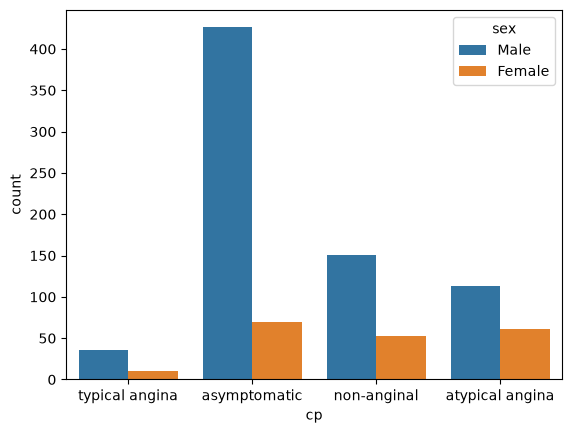

In [152]:
# count plot of cp column by sex column
sns.countplot(df, x='cp', hue='sex')

# print value counts of cp groupby sex
print(df.groupby('sex')['cp'].value_counts())

cp               dataset      
asymptomatic     Cleveland        144
                 VA Long Beach    131
                 Hungary          123
                 Switzerland       98
atypical angina  Hungary          105
                 Cleveland         51
                 VA Long Beach     14
                 Switzerland        4
non-anginal      Cleveland         86
                 Hungary           54
                 VA Long Beach     47
                 Switzerland       17
typical angina   Cleveland         23
                 Hungary           11
                 VA Long Beach      8
                 Switzerland        4
Name: count, dtype: int64


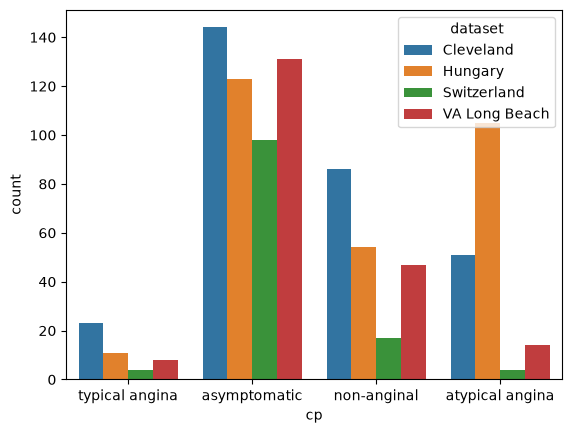

In [153]:
# countplot of cp column by dataset column
sns.countplot(df, x='cp', hue='dataset')

# print valuecount of cp groupby dataset
print(df.groupby('cp')['dataset'].value_counts())

age  cp             
28   atypical angina    1
29   atypical angina    3
30   typical angina     1
31   atypical angina    1
     asymptomatic       1
                       ..
74   non-anginal        2
     typical angina     1
75   asymptomatic       3
76   non-anginal        2
77   asymptomatic       2
Name: count, Length: 156, dtype: int64


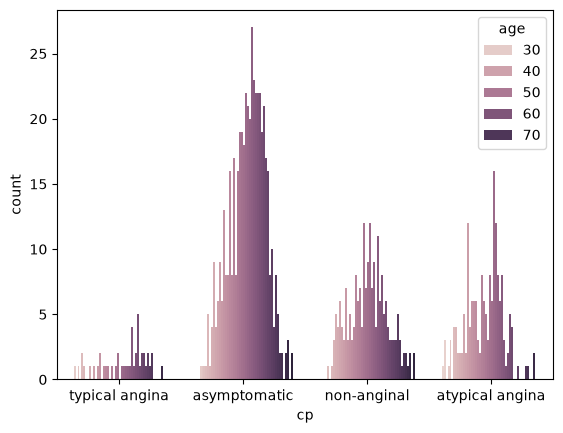

In [154]:
# countplot of cp column by age column
sns.countplot(df, x='cp', hue='age')

# print valuecount of cp column gorupby age column
print(df.groupby('age')['cp'].value_counts())

In [155]:
fig= px.histogram(data_frame=df, x='age', color='cp')
fig.show()

#### Let's explore the trestbps (resting blood pressure) column:

The normal resting blood pressure is 120/80 mm Hg.

In [156]:
# check value counts of trestbps column
df['trestbps'].describe()

count    861.000000
mean     132.132404
std       19.066070
min        0.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64

<Axes: xlabel='trestbps', ylabel='Count'>

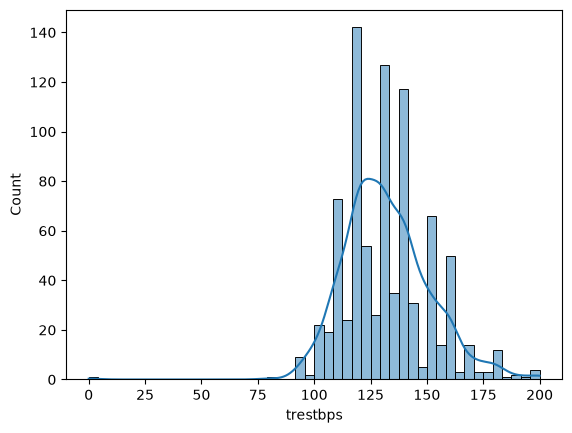

In [157]:
# create a histplot of trestbp column
sns.histplot(df['trestbps'], kde= True)

### Deal with missing values

In [158]:
# Deal with missing values in trestbps column
# find the percentage of missing values in trestbps column
print(f"Percentage of missing values in trestbps column: {df['trestbps'].isnull().sum() / len(df) * 100:.2f}%")

Percentage of missing values in trestbps column: 6.41%


In [159]:
# impute the missing values of trestbps column using iterative imputer
# create an object of iterative imputer
imputer1 = IterativeImputer (max_iter=10, random_state= 43)

# fit the imputer on trestbps column
imputer1.fit(df[['trestbps']])

# transform the data
df['trestbps'] = imputer1.transform(df[['trestbps']])

# check the missing values in trestbps
print(f"Missing values in trestbps: {df['trestbps'].isnull().sum()}")

Missing values in trestbps: 0


In [160]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  920 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [161]:
# impute missing values using iterative imputer for ca, oldpeak, thalch, chol columns
imputer2 = IterativeImputer(max_iter=10, random_state=43)

# fit_transform the imputer on ca, oldpeak, thalch, chol columns
df['ca'] = imputer2.fit_transform(df[['ca']])
df['oldpeak'] = imputer2.fit_transform(df[['oldpeak']])
df['chol'] = imputer2.fit_transform(df[['chol']])
df['thalch'] = imputer2.fit_transform(df[['thalch']])

#### Let's impute missing values in thal column by using ML models

In [162]:
print(f"The missing values in thal column are: {df['thal'].isnull().sum()}")

The missing values in thal column are: 486


In [163]:
df.isnull().sum()[df.isnull().sum()> 0].sort_values(ascending= False)

thal       486
slope      309
fbs         90
exang       55
restecg      2
dtype: int64

In [164]:
# identify features with missing values in more than 10%
missing_data_cols = df.isnull().sum()[df.isnull().sum() > 0].index.tolist()
missing_data_cols

['fbs', 'restecg', 'exang', 'slope', 'thal']

In [165]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  920 non-null    float64
 6   chol      920 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    920 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   920 non-null    float64
 12  slope     611 non-null    str    
 13  ca        920 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [166]:
# seperate columns
categorical_cols = ['thal', 'ca', 'slope', 'exang', 'restecg','fbs', 'cp', 'sex', 'num']
bool_cols = ['fbs', 'exang']
numeric_cols = ['oldpeak', 'thalch', 'chol', 'trestbps', 'age']

In [167]:

# define the function to impute the missing values in thal column

def impute_categorical_missing_data(passed_col):

    df_null = df[df[passed_col].isnull()].copy()
    df_not_null = df[df[passed_col].notnull()].copy()

    X = df_not_null.drop(passed_col, axis=1).copy()
    y = df_not_null[passed_col].copy()

    other_missing_cols = [
        col for col in missing_data_cols if col != passed_col
    ]

    # Encode categorical columns, including pandas string dtype
    categorical_mappings = {}

    for col in X.columns:
        if (
            pd.api.types.is_object_dtype(X[col])
            or pd.api.types.is_string_dtype(X[col])
            or isinstance(X[col].dtype, pd.CategoricalDtype)
            or pd.api.types.is_bool_dtype(X[col])
        ):
            values = X[col].astype("string")
            categories = values.dropna().unique().tolist()
            mapping = {value: i for i, value in enumerate(categories)}
            categorical_mappings[col] = mapping
            X[col] = values.map(mapping).astype(float)

    # Fill missing predictor values so the model receives numeric data
    for col in X.columns:
        if X[col].isnull().any():
            X[col] = X[col].fillna(X[col].median())

    # Encode the target only if it is Boolean
    target_mapping = None
    if passed_col in bool_cols:
        y = y.astype("string")
        target_categories = y.dropna().unique().tolist()
        target_mapping = {
            value: i for i, value in enumerate(target_categories)
        }
        y = y.map(target_mapping)

    # Train and evaluate the classifier
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    rf_classifier = RandomForestClassifier(random_state=42)
    rf_classifier.fit(X_train, y_train)

    y_pred = rf_classifier.predict(X_test)
    acc_score = accuracy_score(y_test, y_pred)

    print(
        "The feature '" + passed_col + "' has been imputed with",
        round(acc_score * 100, 2),
        "accuracy\n"
    )

    # Prepare rows with missing target values
    X_missing = df_null.drop(passed_col, axis=1).copy()

    for col in X_missing.columns:
        if col in categorical_mappings:
            values = X_missing[col].astype("string")
            X_missing[col] = values.map(
                categorical_mappings[col]
            ).astype(float)
        else:
            X_missing[col] = pd.to_numeric(
                X_missing[col], errors="coerce"
            )

        if X_missing[col].isnull().any():
            X_missing[col] = X_missing[col].fillna(
                X[col].median()
            )

    if len(df_null) > 0:
        predictions = rf_classifier.predict(X_missing)

        if target_mapping is not None:
            reverse_mapping = {
                value: key for key, value in target_mapping.items()
            }
            predictions = pd.Series(predictions).map(
                reverse_mapping
            ).to_numpy()

        df_null.loc[:, passed_col] = predictions

    df_combined = pd.concat([df_not_null, df_null])
    return df_combined[passed_col].reindex(df.index)


def impute_continuous_missing_data(passed_col):

    df_null = df[df[passed_col].isnull()].copy()
    df_not_null = df[df[passed_col].notnull()].copy()

    X = df_not_null.drop(passed_col, axis=1).copy()
    y = df_not_null[passed_col].copy()

    other_missing_cols = [
        col for col in missing_data_cols if col != passed_col
    ]

    # Encode categorical columns, including pandas string dtype
    categorical_mappings = {}

    for col in X.columns:
        if (
            pd.api.types.is_object_dtype(X[col])
            or pd.api.types.is_string_dtype(X[col])
            or isinstance(X[col].dtype, pd.CategoricalDtype)
            or pd.api.types.is_bool_dtype(X[col])
        ):
            values = X[col].astype("string")
            categories = values.dropna().unique().tolist()
            mapping = {value: i for i, value in enumerate(categories)}
            categorical_mappings[col] = mapping
            X[col] = values.map(mapping).astype(float)

    # Fill missing predictor values
    for col in X.columns:
        if X[col].isnull().any():
            X[col] = X[col].fillna(X[col].median())

    # Train and evaluate the regressor
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    rf_regressor = RandomForestRegressor(random_state=42)
    rf_regressor.fit(X_train, y_train)

    y_pred = rf_regressor.predict(X_test)

    print("MAE =", mean_absolute_error(y_test, y_pred), "\n")
    print(
        "RMSE =",
        np.sqrt(mean_squared_error(y_test, y_pred)),
        "\n"
    )
    print("R2 =", r2_score(y_test, y_pred), "\n")

    # Prepare rows with missing target values
    X_missing = df_null.drop(passed_col, axis=1).copy()

    for col in X_missing.columns:
        if col in categorical_mappings:
            values = X_missing[col].astype("string")
            X_missing[col] = values.map(
                categorical_mappings[col]
            ).astype(float)
        else:
            X_missing[col] = pd.to_numeric(
                X_missing[col], errors="coerce"
            )

        if X_missing[col].isnull().any():
            X_missing[col] = X_missing[col].fillna(
                X[col].median()
            )

    if len(df_null) > 0:
        df_null.loc[:, passed_col] = rf_regressor.predict(X_missing)

    df_combined = pd.concat([df_not_null, df_null])
    return df_combined[passed_col].reindex(df.index)


In [168]:
# remove warning
import warnings
warnings.filterwarnings('ignore')

# impute missing values using our functions
for col in missing_data_cols:
    print("Missing Values", col, ":", str(round((df[col].isnull().sum() / len(df)) * 100, 2))+"%")
    if col in categorical_cols:
        df[col] = impute_categorical_missing_data(col)
    elif col in numeric_cols:
        df[col] = impute_continuous_missing_data(col)
    else:
        pass

Missing Values fbs : 9.78%
The feature 'fbs' has been imputed with 78.31 accuracy

Missing Values restecg : 0.22%
The feature 'restecg' has been imputed with 61.96 accuracy

Missing Values exang : 5.98%
The feature 'exang' has been imputed with 78.03 accuracy

Missing Values slope : 33.59%
The feature 'slope' has been imputed with 68.29 accuracy

Missing Values thal : 52.83%
The feature 'thal' has been imputed with 71.26 accuracy



In [169]:
# check missing values
df.isnull().sum()

id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

#### Dealing with outliers

<function matplotlib.pyplot.show(close=None, block=None)>

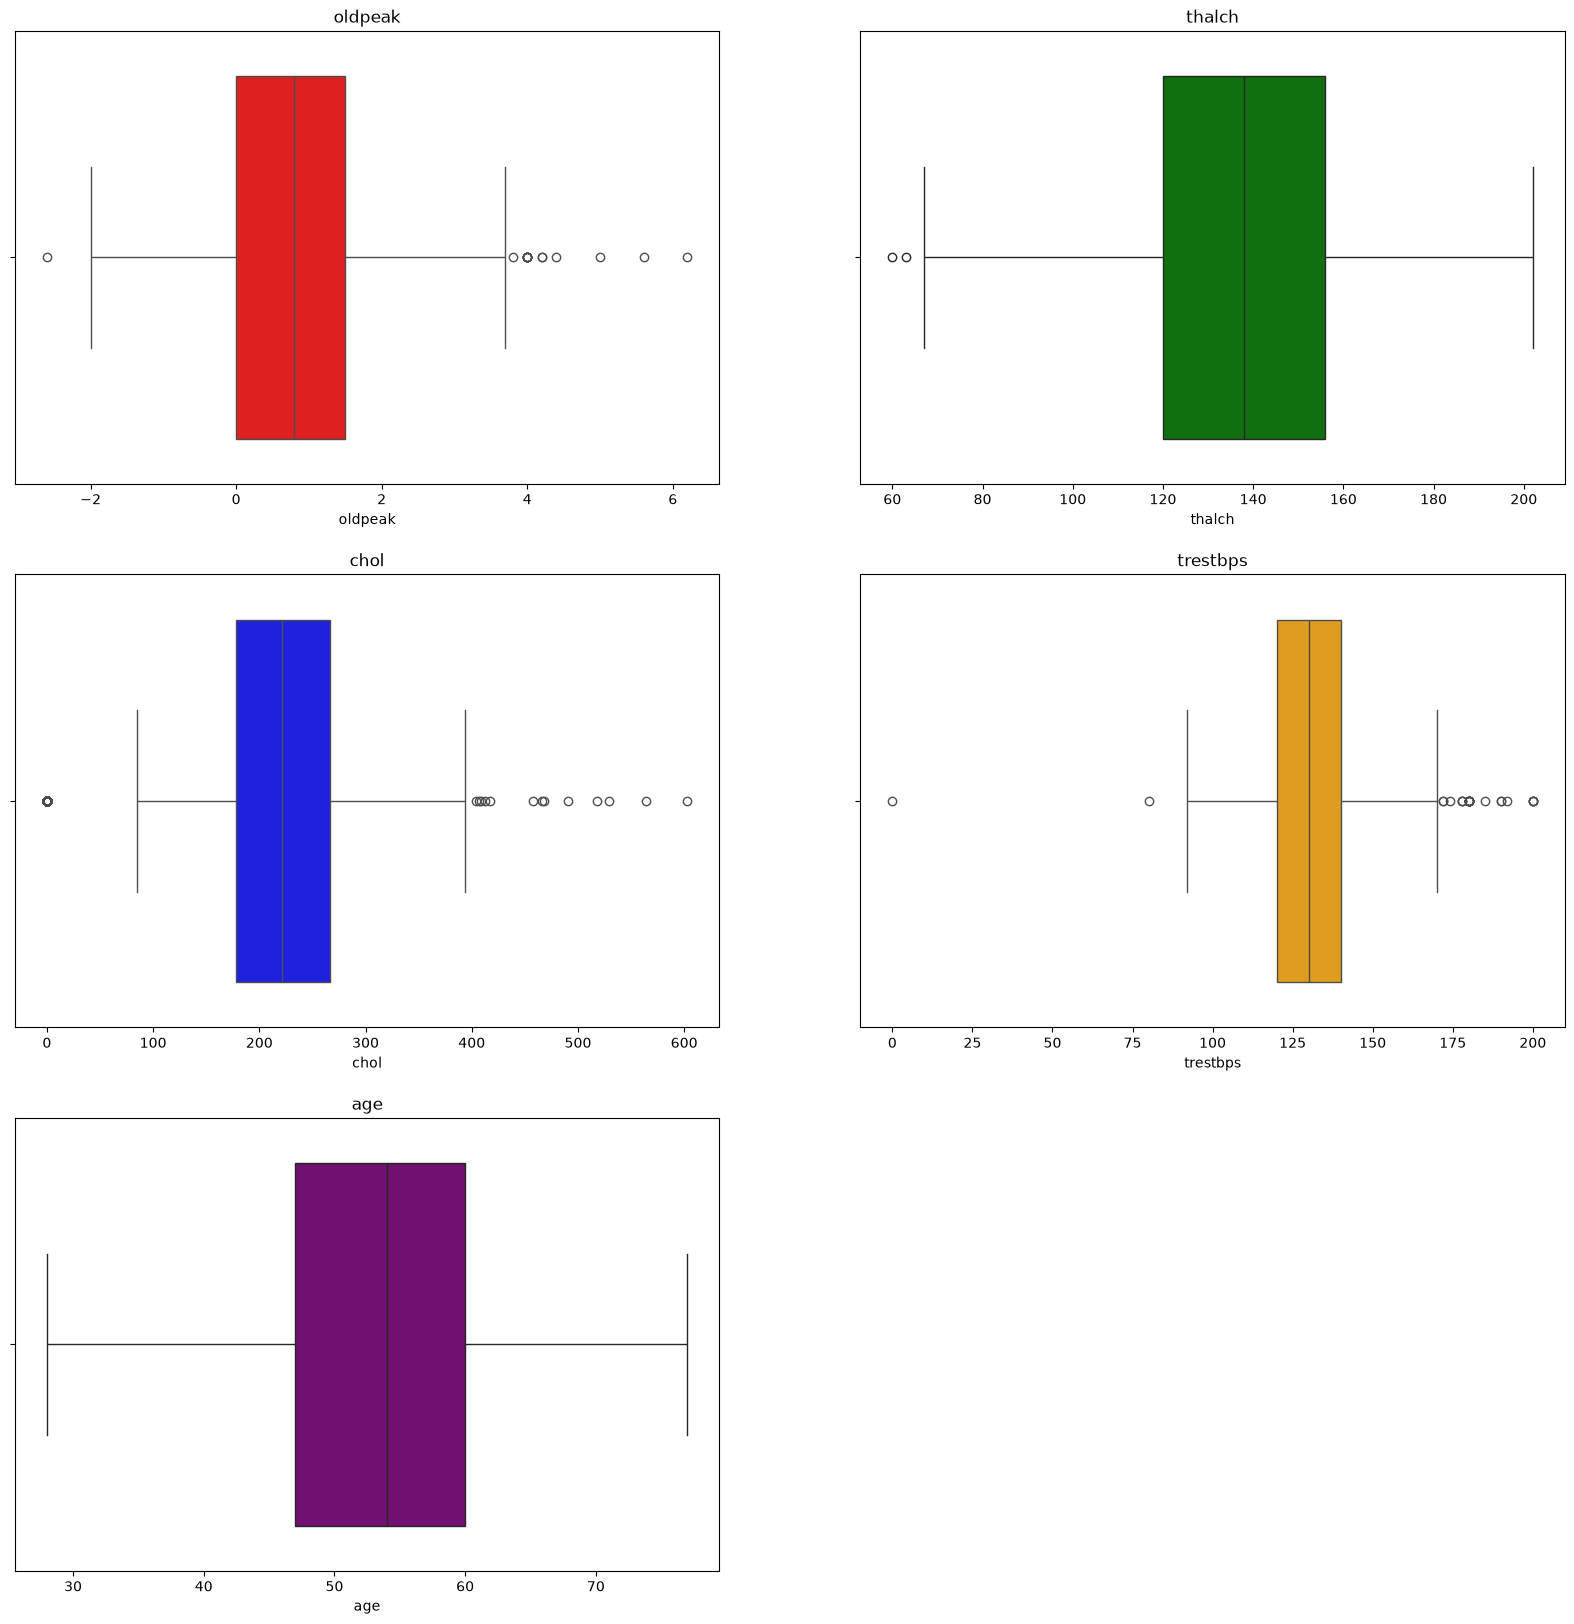

In [170]:
# create a box plots for all numeric columns using for loop and subplot
plt.figure(figsize=(20,20))
colors = ['red', 'green', 'blue', 'orange', 'purple']

for i, col in enumerate(numeric_cols):
    plt.subplot(3, 2, i+1)
    sns.boxplot(x=df[col], color=colors[i])
    plt.title(col)

plt.show

In [171]:
# make vox plots of all the numeric columns using plotly
fig = px.box(data_frame=df, y='age')
fig.show()
fig = px.box(data_frame=df, y='trestbps')
fig.show()
fig = px.box(data_frame=df, y= 'chol')
fig.show()

In [172]:
# print the romw from df where trestbps value is 0
df[df['trestbps']==0]

# remove this row from data
df = df[df['trestbps'] != 0]

In [173]:
# print the row in df where chol is 0
df[df['chol'] ==0]

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
597,598,32,Male,Switzerland,typical angina,95.000000,0.0,False,normal,127.000000,False,0.700000,upsloping,0.676375,normal,1
598,599,34,Male,Switzerland,asymptomatic,115.000000,0.0,False,normal,154.000000,False,0.200000,upsloping,0.676375,normal,1
599,600,35,Male,Switzerland,asymptomatic,132.132404,0.0,False,normal,130.000000,True,0.878788,flat,0.676375,reversable defect,3
600,601,36,Male,Switzerland,asymptomatic,110.000000,0.0,False,normal,125.000000,True,1.000000,flat,0.676375,fixed defect,1
601,602,38,Female,Switzerland,asymptomatic,105.000000,0.0,False,normal,166.000000,False,2.800000,upsloping,0.676375,normal,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
818,819,43,Male,VA Long Beach,asymptomatic,122.000000,0.0,False,normal,120.000000,False,0.500000,upsloping,0.676375,reversable defect,1
819,820,63,Male,VA Long Beach,non-anginal,130.000000,0.0,True,st-t abnormality,160.000000,False,3.000000,flat,0.676375,fixed defect,0
822,823,48,Male,VA Long Beach,non-anginal,102.000000,0.0,False,st-t abnormality,110.000000,True,1.000000,downsloping,0.676375,reversable defect,1
839,840,56,Male,VA Long Beach,asymptomatic,132.132404,0.0,False,lv hypertrophy,137.545665,True,0.878788,flat,0.676375,reversable defect,1


### Machine Learning

In [174]:
df.columns

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')

In [175]:
df['num'].value_counts()

num
0    411
1    265
2    109
3    106
4     28
Name: count, dtype: int64

In [176]:

# Split the data into features and target
X = df.drop('num', axis=1)
y = df['num']

# Encode categorical features using a separate LabelEncoder for each column
# Store each encoder for inverse transformation later
label_encoders = {}

for col in X.columns:
    if X[col].dtype in ['object', 'category', 'str']:
        label_encoders[col] = LabelEncoder()
        X[col] = label_encoders[col].fit_transform(X[col].astype(str))

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42
)

### List of all the models that we can use to predict the heart disease. These models should be classifiers for multi-class classification.

1. logistic regression
2. KNN
3. NB
4. SVM
5. Decision Tree
6. Random Forest
7. GradientBoost classifier
8. AdaBoost
9. XGBoost
10. lightGBM

In [177]:
# Import all models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# import pipeline
from sklearn.pipeline import Pipeline

# import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [178]:
# Create a list of models to evaluate
models = [
    ('Random Forest', RandomForestClassifier(random_state=42)),
    ('Gradient Boosting', GradientBoostingClassifier(random_state=42)),
    ('Support Vector Machine', SVC(random_state=42)),
    ('Logistic Regression', LogisticRegression(random_state=42)),
    ('K-Nearest Neighbors', KNeighborsClassifier()),
    ('Decision Tree', DecisionTreeClassifier(random_state=42)),
    ('Ada Boost', AdaBoostClassifier(random_state=42)),
    ('XG Boost', XGBClassifier(random_state=42)),
    ('Naive Bayes', GaussianNB())
]

best_model = None
best_accuracy = 0.0

# Iterate over the models and evaluate their performance
for name, model in models:
    # Create a pipeline for each model
    pipeline = Pipeline([
        # ('imputer', SimpleImputer(strategy='most_frequent')),
        # ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ('model', model)])
    
    # Perform cross-validation
    scores = cross_val_score(pipeline, X_train, y_train, cv=5)
    
    # Calculate mean accuracy
    mean_accuracy = scores.mean()
    
    # Fit the pipeline on the training data
    pipeline.fit(X_train, y_train)
    
    # Make predictions on the test data
    y_pred = pipeline.predict(X_test)
    
    # Calculate accuracy score
    accuracy = accuracy_score(y_test, y_pred)
    
    # Print the performance metrics
    print("Model:", name)
    print("Cross-validation Accuracy:", mean_accuracy)
    print("Test Accuracy:", accuracy)
    print()
    
    # Check if the current model has the best accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = pipeline

# Retrieve the best model
print("Best Model:", best_model)

# save the model
import pickle
pickle.dump(best_model, open('heart_disease_model.pkl', 'wb'))

Model: Random Forest
Cross-validation Accuracy: 0.6329820736434109
Test Accuracy: 0.6086956521739131

Model: Gradient Boosting
Cross-validation Accuracy: 0.6360586240310078
Test Accuracy: 0.6630434782608695

Model: Support Vector Machine
Cross-validation Accuracy: 0.5770106589147287
Test Accuracy: 0.5869565217391305

Model: Logistic Regression
Cross-validation Accuracy: 0.5178415697674419
Test Accuracy: 0.4963768115942029

Model: K-Nearest Neighbors
Cross-validation Accuracy: 0.5769985465116279
Test Accuracy: 0.5978260869565217

Model: Decision Tree
Cross-validation Accuracy: 0.6019137596899224
Test Accuracy: 0.5797101449275363

Model: Ada Boost
Cross-validation Accuracy: 0.63140746124031
Test Accuracy: 0.6413043478260869

Model: XG Boost
Cross-validation Accuracy: 0.6282218992248062
Test Accuracy: 0.6340579710144928

Model: Naive Bayes
Cross-validation Accuracy: 0.5708091085271317
Test Accuracy: 0.5398550724637681

Best Model: Pipeline(steps=[('model', GradientBoostingClassifier(rando

### Hyperparameter Tuning

In [179]:
# Define the hyperparameter combinations to evaluate
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Initialize the Gradient Boosting model
gb_model = GradientBoostingClassifier(random_state=42)

# Find the best hyperparameters using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Train and evaluate the hyperparameter combinations
grid_search.fit(X_train, y_train)

# Display the best hyperparameters and cross-validation accuracy
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-validation Accuracy:", grid_search.best_score_)

# Evaluate the best model on the test dataset
best_gb_model = grid_search.best_estimator_
y_pred = best_gb_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

# Evaluate performance for each target class
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}
Best Cross-validation Accuracy: 0.6594476744186046
Test Accuracy: 0.6557971014492754

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.90      0.83       117
           1       0.63      0.68      0.66        87
           2       0.19      0.09      0.12        33
           3       0.48      0.41      0.44        34
           4       0.00      0.00      0.00         5

    accuracy                           0.66       276
   macro avg       0.42      0.42      0.41       276
weighted avg       0.61      0.66      0.63       276




### Feature Selection


In [180]:
# Rank features using the training data only
feature_selector = SelectKBest(score_func=f_classif, k='all')
feature_selector.fit(X_train, y_train)

feature_scores = pd.Series(
    feature_selector.scores_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature rankings:")
print(feature_scores)

# Compare different numbers of selected features
feature_counts = [14, 12, 10, 8, 6]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in feature_counts:
    selected_features = feature_scores.head(k).index

    model = GradientBoostingClassifier(
        **grid_search.best_params_,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train[selected_features],
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    print(f"\nNumber of features: {k}")
    print(f"Mean cross-validation accuracy: {scores.mean():.4f}")


Feature rankings:
exang       53.095756
oldpeak     35.266454
cp          32.309137
thalch      32.282680
slope       27.006492
id          26.066254
ca          21.617607
age         21.401547
sex         20.903657
dataset     19.653103
thal        17.592903
chol        14.865486
trestbps     3.898545
restecg      2.983065
fbs          2.740310
dtype: float64

Number of features: 14
Mean cross-validation accuracy: 0.6469

Number of features: 12
Mean cross-validation accuracy: 0.6532

Number of features: 10
Mean cross-validation accuracy: 0.6516

Number of features: 8
Mean cross-validation accuracy: 0.6563

Number of features: 6
Mean cross-validation accuracy: 0.6267


In [181]:
# Select the best 8 features
selected_features = feature_scores.head(8).index.tolist()

# Train the model using the selected features
best_gb_model.fit(X_train[selected_features], y_train)

# Make predictions on the test data
y_pred = best_gb_model.predict(X_test[selected_features])

# Check model accuracy
print("Selected Features:", selected_features)
print("Test Accuracy:", accuracy_score(y_test, y_pred))

# Show the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Selected Features: ['exang', 'oldpeak', 'cp', 'thalch', 'slope', 'id', 'ca', 'age']
Test Accuracy: 0.6557971014492754

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.88      0.82       117
           1       0.63      0.66      0.64        87
           2       0.24      0.15      0.19        33
           3       0.57      0.47      0.52        34
           4       0.00      0.00      0.00         5

    accuracy                           0.66       276
   macro avg       0.44      0.43      0.43       276
weighted avg       0.62      0.66      0.63       276



### Model evaluation with selected features


In [182]:
# Remove the id feature from the selected features
selected_features_without_id = [col for col in selected_features if col != 'id']

# Train the model without id
best_gb_model.fit(X_train[selected_features_without_id], y_train)

# Make predictions on the test data
y_pred_without_id = best_gb_model.predict(X_test[selected_features_without_id])

# Check model accuracy
print("Test Accuracy without id:", accuracy_score(y_test, y_pred_without_id))

Test Accuracy without id: 0.5797101449275363


### Model Selection Using Hyperparameter Tuning

In [183]:

# Define candidate models and their hyperparameter grids

# from sklearn.preprocessing import StandardScaler

models_and_params = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, random_state=42))
        ]),
        {"model__C": [0.1, 1, 10]}
    ),

    "KNN": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        {
            "model__n_neighbors": [3, 5, 7],
            "model__weights": ["uniform", "distance"]
        }
    ),

    "SVM": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC())
        ]),
        {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [None, 5, 10],
            "min_samples_split": [2, 5]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 10],
            "min_samples_split": [2, 5]
        }
    ),

    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3]
        }
    ),

    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.5, 1.0]
        }
    ),

    "Gaussian Naive Bayes": (
        GaussianNB(),
        {"var_smoothing": [1e-9, 1e-8, 1e-7]}
    ),

    "XGBoost": (
        XGBClassifier(
            random_state=42,
            eval_metric="mlogloss",
            n_jobs=1
        ),
        {
            "n_estimators": [50, 100],
            "max_depth": [3, 5],
            "learning_rate": [0.05, 0.1]
        }
    ),

    "LightGBM": (
        LGBMClassifier(
            random_state=42,
            verbosity=-1,
            n_jobs=1
        ),
        {
            "n_estimators": [50, 100],
            "max_depth": [-1, 5],
            "learning_rate": [0.05, 0.1]
        }
    )
}

print("Updated model configurations:", len(models_and_params))

for name, (model, _) in models_and_params.items():
    print(f"{name}: {model}")

Updated model configurations: 10
Logistic Regression: Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])
KNN: Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])
SVM: Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC())])
Decision Tree: DecisionTreeClassifier(random_state=42)
Random Forest: RandomForestClassifier(random_state=42)
Gradient Boosting: GradientBoostingClassifier(random_state=42)
AdaBoost: AdaBoostClassifier(random_state=42)
Gaussian Naive Bayes: GaussianNB()
XGBoost: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None


### Fair Comparison of Selected Models

In [184]:
# Use the same seven selected features for both models
X_train_fair = X_train[selected_features_without_id]

# Use identical stratified cross-validation splits
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Compare the two candidate models
models_to_compare = {
    "Logistic Regression": best_model,
    "Gradient Boosting": best_gb_model
}

comparison_results = []

for name, model in models_to_compare.items():
    scores = cross_val_score(
        model,
        X_train_fair,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    comparison_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

comparison_df = (
    pd.DataFrame(comparison_results)
    .sort_values("Mean CV Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))


,Model,Mean CV Accuracy,Standard Deviation
0,Gradient Boosting,0.5816,0.0319
1,Logistic Regression,0.5428,0.0284


### Ensemble Learning

In [185]:
# Bagging

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=0.8,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

bagging_scores = cross_val_score(
    bagging_model,
    X_train_fair,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Bagging Classifier")
print("Fold accuracies:", bagging_scores.round(4))
print(f"Mean CV accuracy: {bagging_scores.mean():.4f}")
print(f"Standard deviation: {bagging_scores.std():.4f}")


Bagging Classifier
Fold accuracies: [0.5504 0.5814 0.5659 0.5391 0.5312]
Mean CV accuracy: 0.5536
Standard deviation: 0.0181


In [186]:
# Boosting

# Evaluate boosting models using the same features and CV folds
boosting_models = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        learning_rate=0.5,
        random_state=42
    ),
    "Gradient Boosting": best_gb_model,
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1,
        n_jobs=1
    )
}

boosting_results = []

for name, model in boosting_models.items():
    scores = cross_val_score(
        model,
        X_train_fair,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    boosting_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

boosting_comparison_df = (
    pd.DataFrame(boosting_results)
    .sort_values("Mean CV Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(boosting_comparison_df.round(4))


,Model,Mean CV Accuracy,Standard Deviation
0,Gradient Boosting,0.5816,0.0319
1,AdaBoost,0.5801,0.0173
2,XGBoost,0.5786,0.0241
3,LightGBM,0.5630,0.0320


In [187]:
# Stacking
stacking_model = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=2000, random_state=42)),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )),
        ("gb", GradientBoostingClassifier(
            n_estimators=50,
            learning_rate=0.1,
            max_depth=2,
            random_state=42
        ))
    ],
    final_estimator=LogisticRegression(max_iter=2000, random_state=42),
    cv=5,
    n_jobs=-1
)

stacking_scores = cross_val_score(
    stacking_model,
    X_train_fair,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

stacking_results_df = pd.DataFrame([{
    "Model": "Stacking Classifier",
    "Mean CV Accuracy": stacking_scores.mean(),
    "Standard Deviation": stacking_scores.std()
}])

display(stacking_results_df.round(4))


,Model,Mean CV Accuracy,Standard Deviation
0,Stacking Classifier,0.5972,0.0225


### Final model evaluation

Selected Model: Logistic Regression
Test Accuracy: 0.5942

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       117
           1       0.51      0.56      0.54        87
           2       0.31      0.24      0.27        33
           3       0.55      0.32      0.41        34
           4       0.14      0.20      0.17         5

    accuracy                           0.59       276
   macro avg       0.45      0.43      0.43       276
weighted avg       0.59      0.59      0.58       276



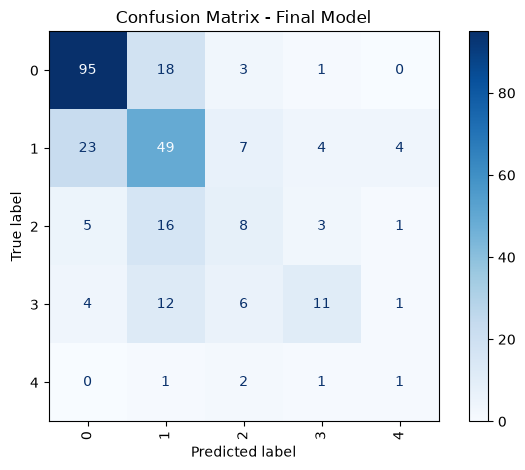

In [188]:
# Prepare test data using the same selected features
X_test_selected = X_test[selected_features_without_id]

# Fit the selected model on the training data
best_model.fit(X_train_fair, y_train)

# Predict on the held-out test set
y_pred_final = best_model.predict(X_test_selected)

# Display evaluation metrics
print("Selected Model:", best_model_name)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_final):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final, zero_division=0))

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    cmap="Blues",
    xticks_rotation="vertical"
)

plt.title("Confusion Matrix - Final Model")
plt.tight_layout()
plt.show()


### Model performance visualization

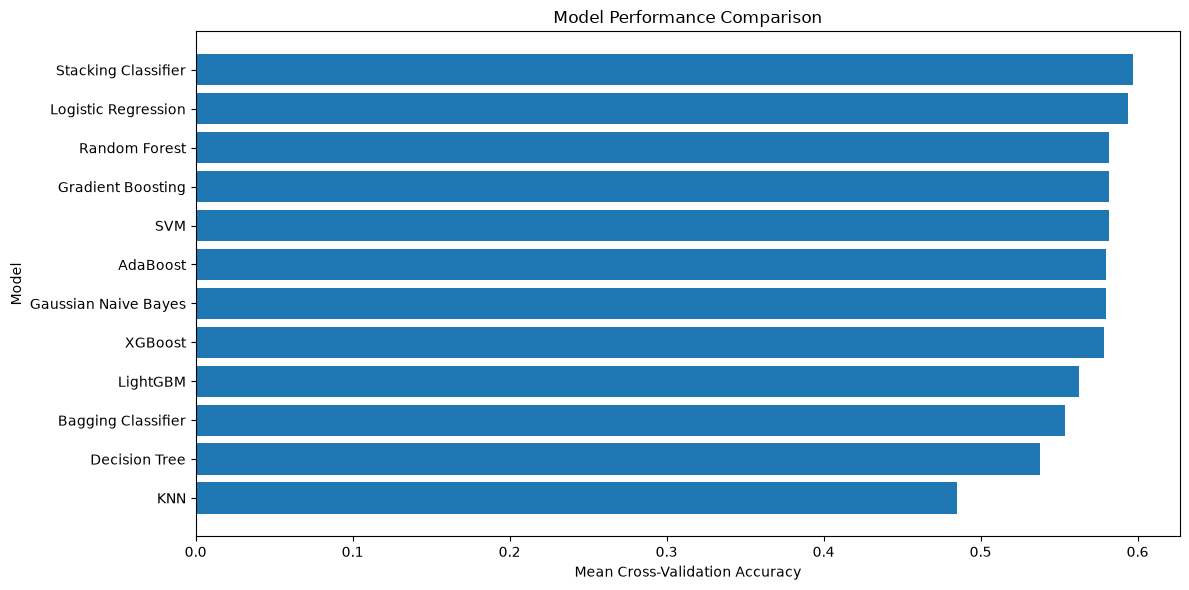

In [189]:
# Combine results from model selection and ensemble experiments

individual_results = model_results[
    ["Model", "CV Accuracy"]
].rename(columns={"CV Accuracy": "Mean CV Accuracy"})

ensemble_results = pd.concat(
    [
        boosting_comparison_df[["Model", "Mean CV Accuracy"]],
        stacking_results_df[["Model", "Mean CV Accuracy"]],
        pd.DataFrame([{
            "Model": "Bagging Classifier",
            "Mean CV Accuracy": bagging_scores.mean()
        }])
    ],
    ignore_index=True
)

all_model_results = pd.concat(
    [individual_results, ensemble_results],
    ignore_index=True
)

all_model_results = (
    all_model_results
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("Mean CV Accuracy", ascending=False)
    .reset_index(drop=True)
)

# Plot comparison
plt.figure(figsize=(12, 6))
plt.barh(
    all_model_results["Model"],
    all_model_results["Mean CV Accuracy"]
)
plt.xlabel("Mean Cross-Validation Accuracy")
plt.ylabel("Model")
plt.title("Model Performance Comparison")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Selected Model: Logistic Regression
Test Accuracy: 0.5942

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       117
           1       0.51      0.56      0.54        87
           2       0.31      0.24      0.27        33
           3       0.55      0.32      0.41        34
           4       0.14      0.20      0.17         5

    accuracy                           0.59       276
   macro avg       0.45      0.43      0.43       276
weighted avg       0.59      0.59      0.58       276



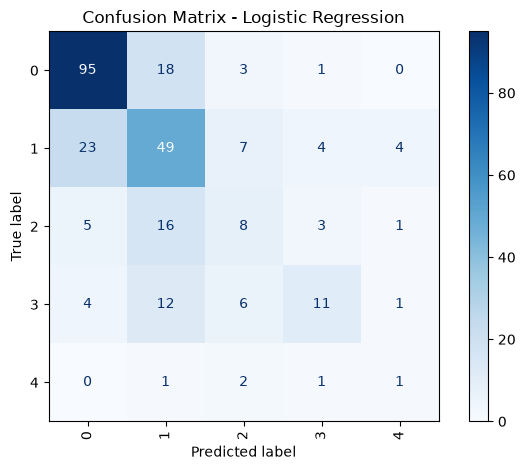

In [190]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train the newly selected model
best_model.fit(X_train_fair, y_train)

# Predict on the independent test set
X_test_selected = X_test[selected_features_without_id]
y_pred_final = best_model.predict(X_test_selected)

# Evaluate the model
print("Selected Model:", best_model_name)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_final):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final, zero_division=0))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    cmap="Blues",
    xticks_rotation="vertical"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

#### outputs:
1. The minimum age to have a heart disease starts from 28 years old.
2. Most of the people get heart disease at the age of 53-54 years.
3. Most of the males and females are with heart disease at the age of 54-55 years.
4. Male percentage in data:  78.913043%
5. Female percentage in data:  21.086957%
6. Males are:  274.226804% more than females
7. We have highest number of people from Cleaveland(304) and lowest from Switzerland(123).
    1. The highest number of females in this dataset are from cleveland(97) and lowest females are from VA long beach(6).
    2. The highest number of males are from Hungary (212) and lowest from Switzerland (113).
8. `The observations about mean, median and mode of age column, grouped by dataset column.`

    1. Mean of Dataset:\
        Cleveland-------54.351974\
        Hungary-------47.894198\
        Switzerland------55.317073\
        VA Long Beach------59.350000

    2. Median of Dataset:\
        Cleveland------55.5\
        Hungary------49.0\
        Switzerland------56.0\
        VA Long Beach------60.0

    3. Mode of Dataset:\
        Cleveland------58\
        Hungary------54\
        Switzerland------61\
        VA Long Beach------[62, 63]

9. `The observations about cp(Chest Pain) column.`
    1. #### The value count of cp groupby sex are:
        `Female...`\
        asymptomatic.....70\
        atypical angina.....61\
        non-anginal.....53\
        typical angina.....10

        `Male...`\
        asymptomatic.....426\
        non-anginal.....151\
        atypical angina.....113\
        typical angina.....36
    
    2. #### The value count of cp groupby dataset are:
        `Asymptomatic...`\
                Cleveland        144\
                 VA Long Beach    131\
                 Hungary          123\
                 Switzerland       98

        `Atypical angina...`\
                Hungary          105\
                Cleveland         51\
                VA Long Beach     14\
                Switzerland        4

        `Non-anginal...`\
                Cleveland         86\
                Hungary           54\
                VA Long Beach     47\
                Switzerland       17

        `Typical angina...`\
                Cleveland         23\
                Hungary           11\
                VA Long Beach      8\
                Switzerland        4

    3. #### The value count of cp groupby age:

        `age`........`cp`\
        28..........atypical angina    (1)\
        29..........atypical angina    (3)\
        30..........typical angina     (1)\
        31..........atypical angina    (1)\
        31..........asymptomatic       (1)\
        74..........non-anginal        (2)\
        74..........typical angina     (1)\
        75..........asymptomatic       (3)\
        76..........non-anginal        (2)\
        77..........asymptomatic       (2)
10. `Observation about handling missing categorical values using ML models:`\
    In this step, I implemented and tested a reusable function, impute_categorical_missing_data(), to handle missing values in categorical columns of the heat disease dataset.\
    `Key Observations are:`
    1. The function separates rows with missing target values from rows with available values.
    2. Categorical predictor variables are encoded into numerical representations so that they can be processed by machine learning models.
    3. A Random Forest Classifier is trained using the available target values to predict missing categorical values.
    4. The model's performance is evaluated using a train-test split and accuracy score
    5. The function returns the target column with predicted values filled in for the missing entries.\
  `Testing and Result:`\
    I tested the function using the fbs column. The model achieved 77.72% accuracy on the test split. The returned result contained 920 rows, matching the original dataset, and zero missing values
11. `Observation about Outlier Detection and Handling`
    1. Created box plots using Seaborn and Plotly to inspect numerical columns for potential outliers.
    2. Checked the trestbps column for zero values and removed the row containing an invalid zero blood pressure reading.
    3. Checked the chol column for zero values to identify potentially invalid measurements.

12. `Observations from model output.`\
    `Model: Random Forest`\
    Cross-validation Accuracy: 0.6329820736434109\
    Test Accuracy: 0.6086956521739131

    `Model: Gradient Boosting`\
    Cross-validation Accuracy: 0.6360586240310078\
    Test Accuracy: 0.6630434782608695

    `Model: Support Vector Machine`\
    Cross-validation Accuracy: 0.5770106589147287\
    Test Accuracy: 0.5869565217391305

    `Model: Logistic Regression`\
    Cross-validation Accuracy: 0.5178415697674419\
    Test Accuracy: 0.4963768115942029

    `Model: K-Nearest Neighbors`\
    Cross-validation Accuracy: 0.5769985465116279\
    Test Accuracy: 0.5978260869565217

    `Model: Decision Tree`\
    Cross-validation Accuracy: 0.6019137596899224\
    Test Accuracy: 0.5797101449275363

    `Model: Ada Boost`\
    Cross-validation Accuracy: 0.5708091085271317\
    Test Accuracy: 0.5398550724637681
13. `Observations from feature selection:`\
    (a) 14 features: 0.6469 CV accuracy.\
    (b) 12 features: 0.6532 CV accuracy.\
    (c) 10 features: 0.6516 CV accuracy.\
    (d) 8 features: 0.6563 CV accuracy.\
    (e) 6 features: 0.6267 CV accuracy.\
    (f) The 8-feature selection achieved the highest reported accuracy.\
    (g) Removed id from the selected predictors because it is an identifier rather than a meaningful predictive feature.\
    (i) Final selected features: exang, oldpeak, cp, thalch, slope, ca, age.
14. `Observations from hyperparameter tuning and automated model selection:`
    1. Compared 10 classification models using GridSearchCV and 5-fold stratified cross-validation.
    2. Applied StandardScaler inside the pipelines for Logistic Regression, KNN, and SVM.
    3. Logistic Regression achieved the highest cross-validation accuracy in the updated model-selection experiment.
    4. Best Model: Logistic Regression
    5. Best CV Accuracy: 0.5940
    6. Best Parameters: C = 1
    7. Model Comparison:
    8. Logistic Regression: 0.5940
    9. XGBoost: 0.5863
    10. LightGBM: 0.5832
    11. Random Forest: 0.5816
    12. Gradient Boosting: 0.5816
    13. SVM: 0.5816
    14. AdaBoost: 0.5801
    15. Gaussian Naive Bayes: 0.5800
    16. Decision Tree: 0.5381
    17. KNN: 0.4852
15. `Observations from ensemble learning:`
    1. Evaluated Bagging using a Decision Tree base estimator and 100 estimators.
    2. Bagging mean CV accuracy: 0.5536.
    3. Bagging standard deviation: 0.0181.
    4. Evaluated Boosting using AdaBoost, Gradient Boosting, XGBoost, and LightGBM.
    5. Evaluated Stacking using Logistic Regression, Random Forest, and Gradient Boosting as base estimators.
    6. Boosting and Stacking comparison results were generated in their respective output cells.
16. `Observations from final model evaluation:`
    `Selected Model: Logistic Regression`

    Cross-validation Accuracy: 59.40%.

    Test Accuracy: 59.42%.

    Weighted F1-score: 0.58.

    Macro F1-score: 0.43.

    `Classification Report:`

    Class 0: Precision 0.75, Recall 0.81, F1-score 0.78.

    Class 1: Precision 0.51, Recall 0.56, F1-score 0.54.

    Class 2: Precision 0.31, Recall 0.24, F1-score 0.27.

    Class 3: Precision 0.55, Recall 0.32, F1-score 0.41.

    Class 4: Precision 0.14, Recall 0.20, F1-score 0.17.

    Generated a confusion matrix to evaluate classification performance across the target classes.

    Performance varied across classes, with lower scores for less frequent classes.
17. `Final Conclusion and Best Model Selection:`
    Evaluated 10 classification models using GridSearchCV and StratifiedKFold.

    Selected `Logistic Regression` as the best model based on cross-validation accuracy.

    Best CV Accuracy: 59.40%.

    Test Accuracy: 59.42%.

    Best Parameter: C = 1.

    The model provides a baseline for further improvement, especially for minority classes.
